In [1]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 46.9 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


In [2]:
import pennylane as qml
from pennylane import numpy as pnp
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import kagglehub

In [3]:
# Download latest version
path = kagglehub.dataset_download("hassan06/nslkdd")

print("Path to dataset files:", path)
df = pd.read_csv(path +'/KDDTrain+.txt', header=None)

print(df.shape)
df.head()

100%|██████████| 13.9M/13.9M [00:00<00:00, 58.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hassan06/nslkdd/versions/1
(125973, 43)


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [4]:
# ---------------------------------------------------------
# 1. DATA PREPARATION FOR UNSUPERVISED LEARNING
# ---------------------------------------------------------
X_brut = df.iloc[:, 0:41]
y_brut = df.iloc[:, 41]
y_binaire = pnp.where(y_brut == 'normal', 0, 1) # 0: Normal, 1: Attack

X_encode = pd.get_dummies(X_brut, columns=[1, 2, 3], drop_first=True)

# PCA & Scaling (4 qubits : 2 latent qubits + 2 trash qubits)
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_encode.values)
scaler = MinMaxScaler(feature_range=(0, pnp.pi))
X_scaled = scaler.fit_transform(X_pca)

# TRAINING: Filter ONLY NORMAL traffic (y == 0)
X_normal = X_scaled[y_binaire == 0]
X_train = X_normal[:200]

# TEST: A mixed set (50 normal + 50 attack)
X_test_normal = X_scaled[y_binaire == 0][200:250]
X_test_attack = X_scaled[y_binaire == 1][:50]

In [5]:
# ---------------------------------------------------------
# 2. CONSTRUCTING THE QUANTUM AUTOENCODER (QAE)
# ---------------------------------------------------------
N_QUBITS = 4
N_TRASH = 2
N_LATENT = N_QUBITS - N_TRASH
N_LAYERS = 3

dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev)
def qae_circuit(weights, x):
    # Encode the input state on 4 qubits
    qml.AngleEmbedding(x, wires=range(N_QUBITS))

    # Parameterized compression circuit
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))

    # Measure the probability on the 'trash qubits' (qubits 2 and 3)
    return qml.probs(wires=range(N_LATENT, N_QUBITS))

# Anomaly score = Reconstruction error (1 - Probability of state |00>)
def anomaly_score(weights, x):
    prob_state_00 = qae_circuit(weights, x)[0]
    return 1.0 - prob_state_00

def cost_function(weights, X_batch):
    scores = [anomaly_score(weights, x) for x in X_batch]
    return pnp.mean(pnp.array(scores))

# Initialize weights
pnp.random.seed(42)
weights = pnp.random.random(size=qml.StronglyEntanglingLayers.shape(n_layers=N_LAYERS, n_wires=N_QUBITS))
opt = qml.AdamOptimizer(stepsize=0.03)

In [6]:
# ---------------------------------------------------------
# 3. TRAINING LOOP (Learning the normal pattern)
# ---------------------------------------------------------
epochs = 30
batch_size = 25

print("Starting QAE training on NORMAL traffic only...\n")
for epoch in range(epochs):
    indices = pnp.random.choice(len(X_train), batch_size, replace=False)
    X_b = X_train[indices]

    weights, cost = opt.step_and_cost(lambda w: cost_function(w, X_b), weights)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{epochs} | Reconstruction loss: {cost:.4f}")

Starting QAE training on NORMAL traffic only...

Epoch  1/30 | Reconstruction loss: 0.5458
Epoch  5/30 | Reconstruction loss: 0.3936
Epoch 10/30 | Reconstruction loss: 0.2097
Epoch 15/30 | Reconstruction loss: 0.1463
Epoch 20/30 | Reconstruction loss: 0.0827
Epoch 25/30 | Reconstruction loss: 0.0563
Epoch 30/30 | Reconstruction loss: 0.0453


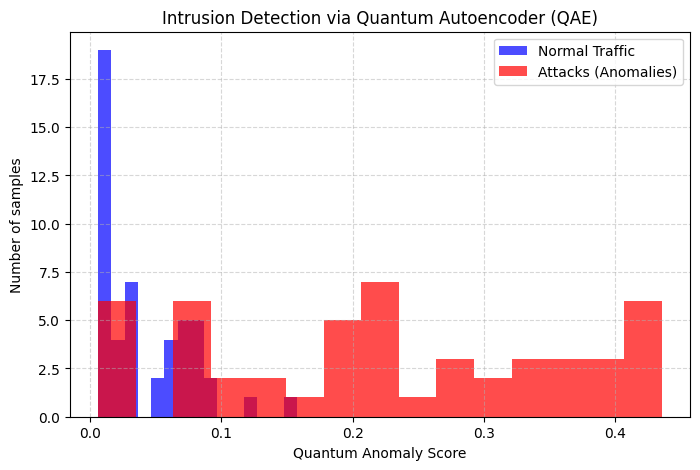

In [7]:
# ---------------------------------------------------------
# 4. EVALUATION AND ANOMALY HISTOGRAM
# ---------------------------------------------------------
# Compute anomaly scores for the test data
scores_normal = [anomaly_score(weights, x) for x in X_test_normal]
scores_attack = [anomaly_score(weights, x) for x in X_test_attack]

# Plotting class separation
plt.figure(figsize=(8, 5))
plt.hist(scores_normal, bins=15, alpha=0.7, label='Normal Traffic', color='blue')
plt.hist(scores_attack, bins=15, alpha=0.7, label='Attacks (Anomalies)', color='red')
plt.xlabel("Quantum Anomaly Score")
plt.ylabel("Number of samples")
plt.title("Intrusion Detection via Quantum Autoencoder (QAE)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()